In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

C:\Users\satwika\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Libraries imported successfully!


In [5]:
import os
print(os.getcwd())


C:\Users\satwika


In [6]:
import os

print(os.path.exists(
    r"C:\Users\satwika\Desktop\CustomerSegmentation\data\OnlineRetail.csv"
))

False


In [7]:
df=pd.read_csv(r"C:\Users\satwika\Desktop\CustomerSegmentation\data\online_retail.csv",encoding="latin1"
              )
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1067371
Number of Columns: 8


In [9]:
print("Columns in Dataset:")

for column in df.columns:
    print(column)

Columns in Dataset:
Invoice
StockCode
Description
Quantity
InvoiceDate
Price
Customer ID
Country


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


In [11]:
df.describe(include='all')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,1067371,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364.000000,1067371
unique,53628,5305,5698,NaN,47635,NaN,NaN,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2010-12-06 16:57:00,NaN,NaN,United Kingdom
freq,1350,5829,5918,NaN,1350,NaN,NaN,981330
mean,NaN,NaN,NaN,9.938898e+00,NaN,4.649388e+00,15324.638504,NaN
std,NaN,NaN,NaN,1.727058e+02,NaN,1.235531e+02,1697.464450,NaN
min,NaN,NaN,NaN,-8.099500e+04,NaN,-5.359436e+04,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000e+00,NaN,1.250000e+00,13975.000000,NaN
50%,NaN,NaN,NaN,3.000000e+00,NaN,2.100000e+00,15255.000000,NaN
75%,NaN,NaN,NaN,1.000000e+01,NaN,4.150000e+00,16797.000000,NaN


In [12]:
missing_values = df.isnull().sum()

missing_values

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [13]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 34335


In [14]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1033036, 8)


In [16]:
df = df.dropna(subset=['Customer ID'])

print("Dataset shape after removing missing Customer IDs:")
print(df.shape)

Dataset shape after removing missing Customer IDs:
(797885, 8)


In [17]:
df['Customer ID'] = df['Customer ID'].astype(int)

df['Customer ID'].head()

0    13085
1    13085
2    13085
3    13085
4    13085
Name: Customer ID, dtype: int32

In [18]:
df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    errors='coerce'
)

df['InvoiceDate'].head()

0   2009-12-01 07:45:00
1   2009-12-01 07:45:00
2   2009-12-01 07:45:00
3   2009-12-01 07:45:00
4   2009-12-01 07:45:00
Name: InvoiceDate, dtype: datetime64[us]

In [20]:
cancelled = df[
    df['Invoice'].astype(str).str.startswith('C')
]

print("Cancelled transactions:", len(cancelled))

Cancelled transactions: 18390


In [21]:
df = df[
    ~df['Invoice'].astype(str).str.startswith('C')
]

print("Dataset shape:", df.shape)

Dataset shape: (779495, 8)


In [22]:
df = df[df['Quantity'] > 0]

print("Dataset shape:", df.shape)

Dataset shape: (779495, 8)


In [24]:
df = df[df['Price'] > 0]

print("Dataset shape:", df.shape)

Dataset shape: (779425, 8)


In [25]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

Duplicate rows:
0


In [27]:
df['Revenue'] = df['Quantity'] * df['Price']

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [28]:
print("Total Revenue:", round(df['Revenue'].sum(), 2))
print("Average Transaction Revenue:", round(df['Revenue'].mean(), 2))

Total Revenue: 17374804.27
Average Transaction Revenue: 22.29


In [29]:
total_revenue = df['Revenue'].sum()
total_customers = df['Customer ID'].nunique()
total_orders = df['Invoice'].nunique()
total_products = df['StockCode'].nunique()
print("Total Revenue       :", round(total_revenue, 2))
print("Total Customers     :", total_customers)
print("Total Orders        :", total_orders)
print("Total Products      :", total_products)

Total Revenue       : 17374804.27
Total Customers     : 5878
Total Orders        : 36969
Total Products      : 4631


In [30]:
country_revenue = (
    df.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

country_revenue.head(10)

Country
United Kingdom    1.438923e+07
EIRE              6.165705e+05
Netherlands       5.540381e+05
Germany           4.250197e+05
France            3.487690e+05
Australia         1.692835e+05
Spain             1.083325e+05
Switzerland       1.000619e+05
Sweden            9.151582e+04
Denmark           6.858069e+04
Name: Revenue, dtype: float64

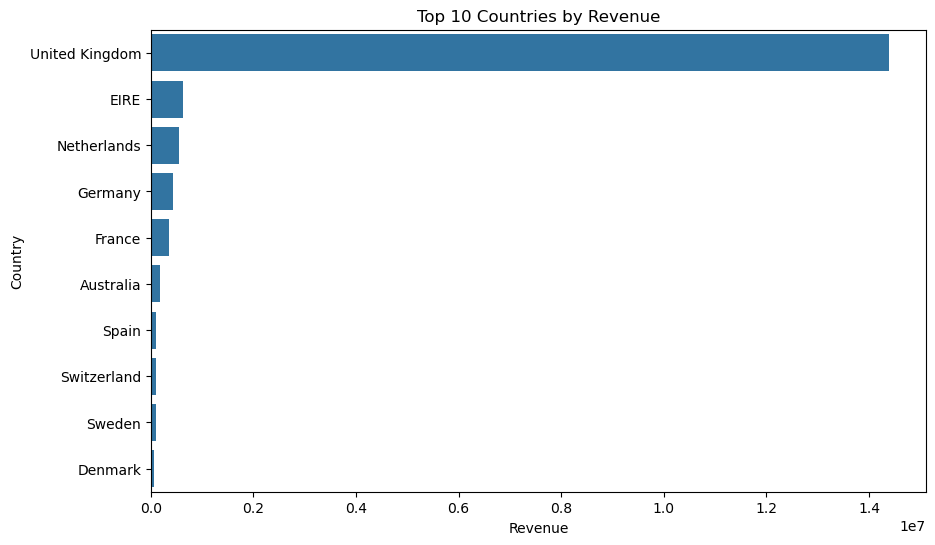

In [31]:
top_countries = country_revenue.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.show()

In [32]:
top_products = (
    df.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
REGENCY CAKESTAND 3 TIER              277656.25
WHITE HANGING HEART T-LIGHT HOLDER    247048.01
PAPER CRAFT , LITTLE BIRDIE           168469.60
Manual                                151777.67
JUMBO BAG RED RETROSPOT               134307.44
POSTAGE                               124648.04
ASSORTED COLOUR BIRD ORNAMENT         124351.86
PARTY BUNTING                         103283.38
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
PAPER CHAIN KIT 50'S CHRISTMAS         76598.18
Name: Revenue, dtype: float64

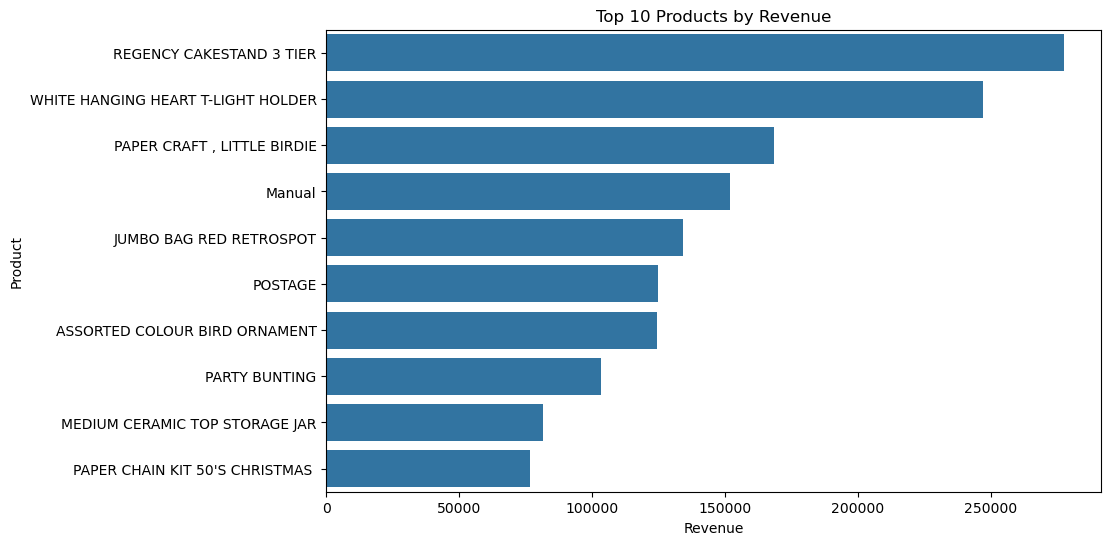

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

In [34]:
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

monthly_revenue = (
    df.groupby('YearMonth')['Revenue']
    .sum()
)

monthly_revenue

YearMonth
2009-12     683504.010
2010-01     555802.672
2010-02     504558.956
2010-03     696978.471
2010-04     591982.002
2010-05     597833.380
2010-06     636371.130
2010-07     589736.170
2010-08     602224.600
2010-09     829013.951
2010-10    1033112.010
2010-11    1166460.022
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517208.440
Freq: M, Name: Revenue, dtype: float64

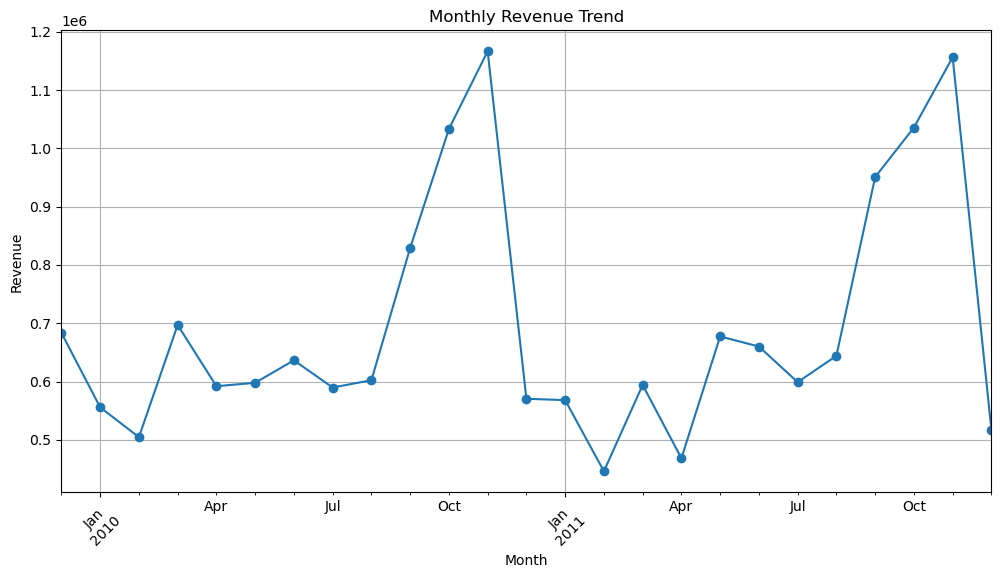

In [35]:
plt.figure(figsize=(12, 6))

monthly_revenue.plot(marker='o')

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [36]:
analysis_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Analysis Date:", analysis_date)

Analysis Date: 2011-12-10 12:50:00


In [37]:
recency = (
    df.groupby('Customer ID')['InvoiceDate']
    .max()
    .apply(lambda x: (analysis_date - x).days)
)

recency.name = 'Recency'

recency.head()

Customer ID
12346    326
12347      2
12348     75
12349     19
12350    310
Name: Recency, dtype: int64

In [38]:
frequency = (
    df.groupby('Customer ID')['Invoice']
    .nunique()
)

frequency.name = 'Frequency'

frequency.head()

Customer ID
12346    12
12347     8
12348     5
12349     4
12350     1
Name: Frequency, dtype: int64

In [39]:
monetary = (
    df.groupby('Customer ID')['Revenue']
    .sum()
)

monetary.name = 'Monetary'

monetary.head()

Customer ID
12346    77556.46
12347     4921.53
12348     2019.40
12349     4428.69
12350      334.40
Name: Monetary, dtype: float64

In [40]:
rfm = pd.concat(
    [recency, frequency, monetary],
    axis=1
)

rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,326,12,77556.46
12347,2,8,4921.53
12348,75,5,2019.40
12349,19,4,4428.69
12350,310,1,334.40


In [41]:
print("Number of customers:", len(rfm))

Number of customers: 5878


In [42]:
rfm.describe()

,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


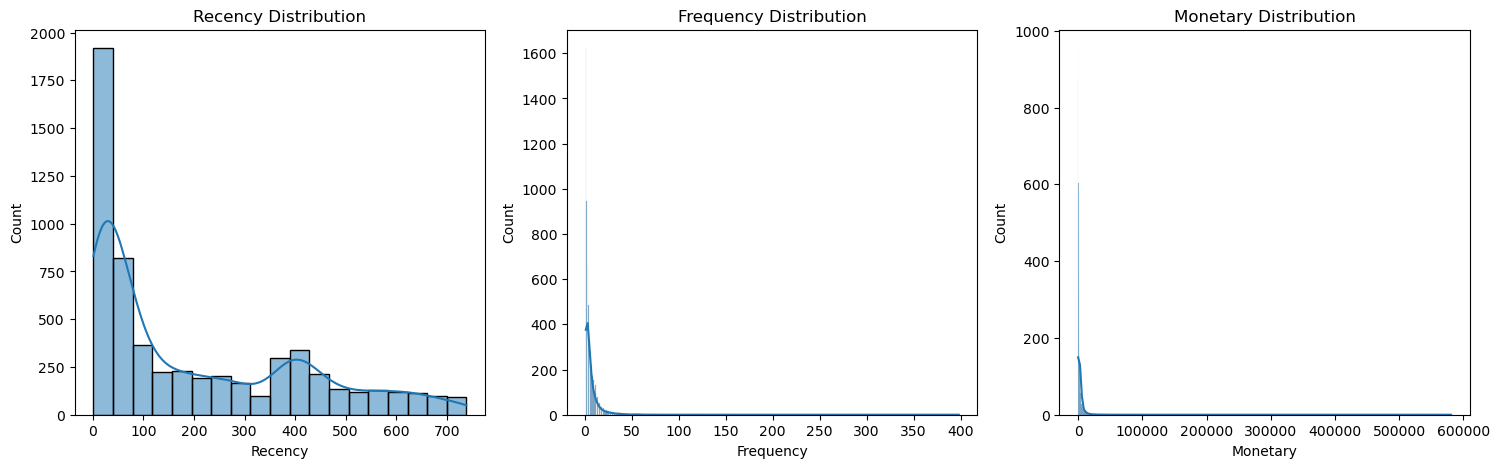

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm['Recency'], kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm['Frequency'], kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm['Monetary'], kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.show()

In [44]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    5,
    labels=[5, 4, 3, 2, 1]
)
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [45]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(int)
    + rfm['F_Score'].astype(int)
    + rfm['M_Score'].astype(int)
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
12346,326,12,77556.46,2,5,5,12
12347,2,8,4921.53,5,4,5,14
12348,75,5,2019.40,3,4,4,11
12349,19,4,4428.69,5,3,5,13
12350,310,1,334.40,2,1,2,5


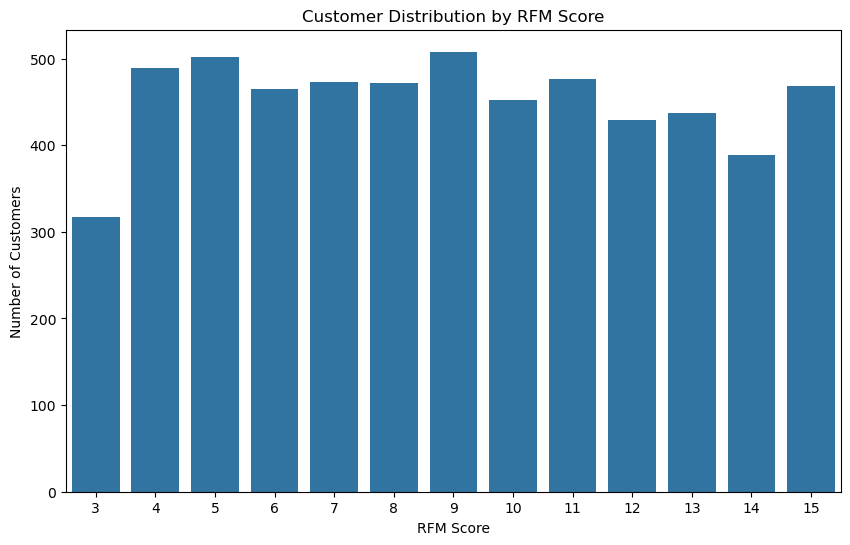

In [46]:
plt.figure(figsize=(10, 6))

sns.countplot(
    x='RFM_Score',
    data=rfm
)

plt.title("Customer Distribution by RFM Score")
plt.xlabel("RFM Score")
plt.ylabel("Number of Customers")

plt.show()

In [47]:
def assign_segment(row):
    
    if row['RFM_Score'] >= 13:
        return 'Champions'
    
    elif row['RFM_Score'] >= 10:
        return 'Loyal Customers'
    
    elif row['RFM_Score'] >= 7:
        return 'Potential Loyalists'
    
    elif row['RFM_Score'] >= 5:
        return 'At Risk'
    
    else:
        return 'Lost Customers'


rfm['Segment'] = rfm.apply(assign_segment, axis=1)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
Customer ID,,,,,,,,
12346,326,12,77556.46,2,5,5,12,Loyal Customers
12347,2,8,4921.53,5,4,5,14,Champions
12348,75,5,2019.40,3,4,4,11,Loyal Customers
12349,19,4,4428.69,5,3,5,13,Champions
12350,310,1,334.40,2,1,2,5,At Risk


In [48]:
segment_counts = (
    rfm['Segment']
    .value_counts()
)

segment_counts

Segment
Potential Loyalists    1453
Loyal Customers        1357
Champions              1295
At Risk                 967
Lost Customers          806
Name: count, dtype: int64

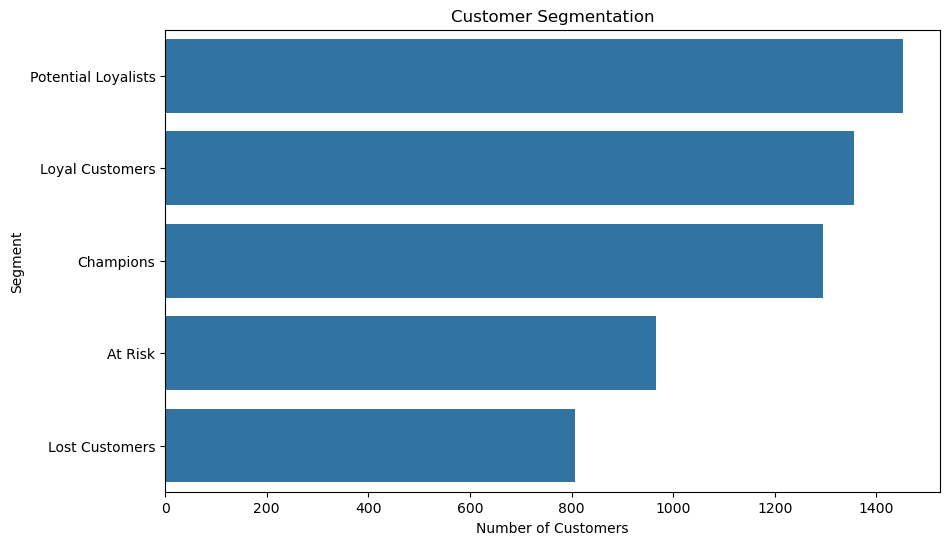

In [49]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_counts.values,
    y=segment_counts.index
)

plt.title("Customer Segmentation")
plt.xlabel("Number of Customers")
plt.ylabel("Segment")

plt.show()

In [50]:
segment_revenue = (
    rfm.groupby('Segment')['Monetary']
    .sum()
    .sort_values(ascending=False)
)

segment_revenue

Segment
Champions              1.253323e+07
Loyal Customers        3.070957e+06
Potential Loyalists    1.238840e+06
At Risk                3.732075e+05
Lost Customers         1.585699e+05
Name: Monetary, dtype: float64

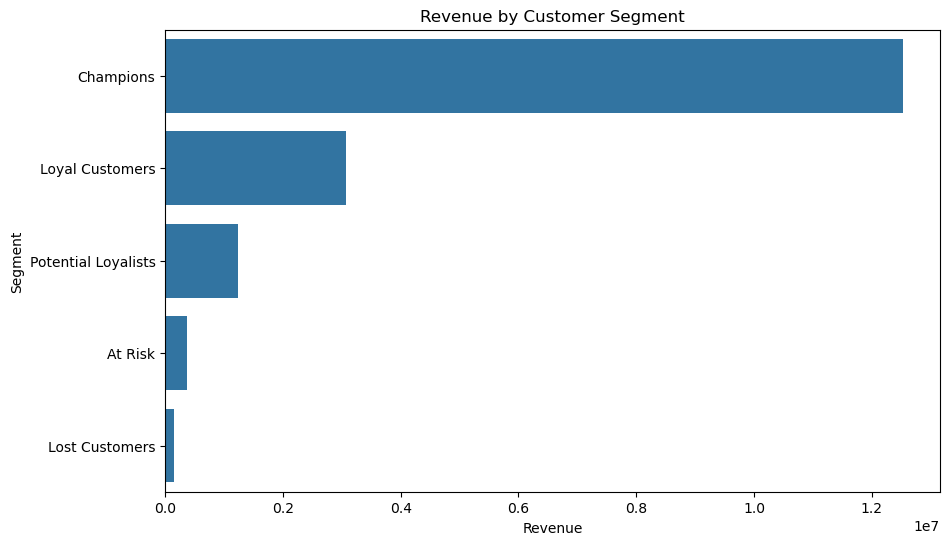

In [51]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_revenue.values,
    y=segment_revenue.index
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Revenue")
plt.ylabel("Segment")

plt.show()

In [52]:
clustering_data = rfm[
    ['Recency', 'Frequency', 'Monetary']
].copy()

clustering_data.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,326,12,77556.46
12347,2,8,4921.53
12348,75,5,2019.40
12349,19,4,4428.69
12350,310,1,334.40


In [53]:
clustering_log = np.log1p(clustering_data)

clustering_log.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,5.789960,2.564949,11.258774
12347,1.098612,2.197225,8.501578
12348,4.330733,1.791759,7.611051
12349,2.995732,1.609438,8.396085
12350,5.739793,0.693147,5.815324


In [54]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(clustering_log)

print("Data standardized successfully!")

Data standardized successfully!


In [55]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    
    inertia.append(kmeans.inertia_)

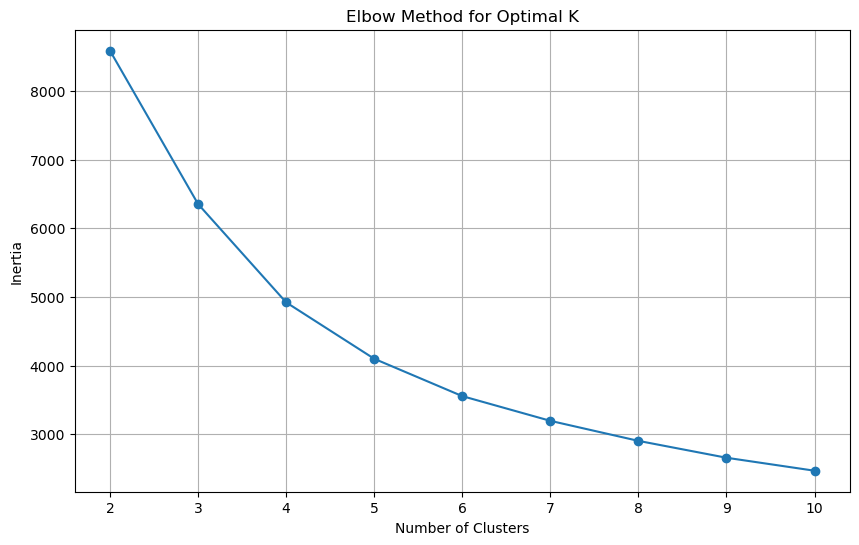

In [56]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    inertia,
    marker='o'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.grid(True)

plt.show()

In [57]:
silhouette_scores = {}

for k in range(2, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    score = silhouette_score(
        rfm_scaled,
        labels
    )
    
    silhouette_scores[k] = score

silhouette_scores

{2: 0.4386023012270002,
 3: 0.3477454491034673,
 4: 0.36497078400572347,
 5: 0.3424961358761568,
 6: 0.3347964327358149,
 7: 0.30663604807644523,
 8: 0.3033153691690236,
 9: 0.29252387787540013,
 10: 0.29052511584322954}

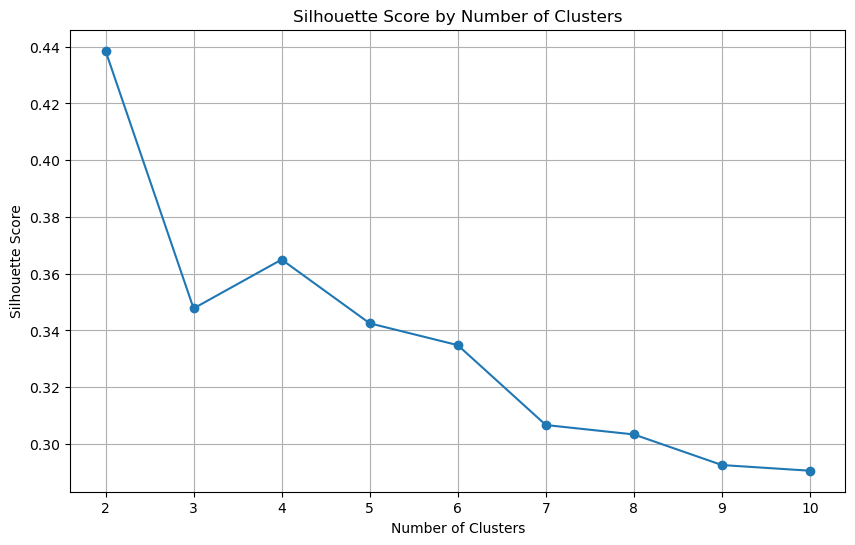

In [58]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker='o'
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.grid(True)

plt.show()

In [59]:
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster
Customer ID,,,,,,,,,
12346,326,12,77556.46,2,5,5,12,Loyal Customers,2
12347,2,8,4921.53,5,4,5,14,Champions,2
12348,75,5,2019.40,3,4,4,11,Loyal Customers,3
12349,19,4,4428.69,5,3,5,13,Champions,1
12350,310,1,334.40,2,1,2,5,At Risk,0


In [60]:
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'RFM_Score': 'mean'
}).round(2)

cluster_summary

,Recency,Frequency,Monetary,RFM_Score
Cluster,,,,
0,394.95,1.38,317.08,4.94
1,28.30,3.05,857.49,9.75
2,27.71,19.28,10731.16,14.06
3,230.07,5.06,1948.50,9.73


In [61]:
cluster_counts = (
    rfm['Cluster']
    .value_counts()
    .sort_index()
)

cluster_counts

Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64

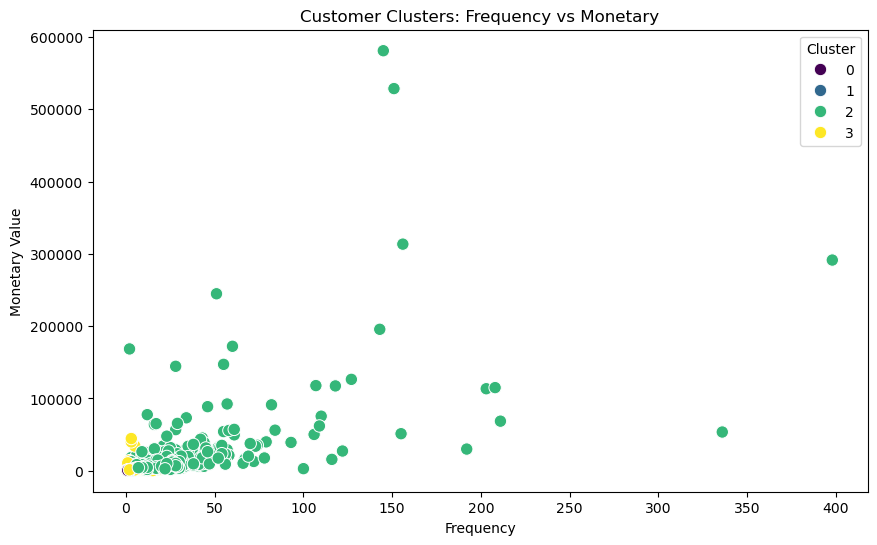

In [62]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=80
)

plt.title("Customer Clusters: Frequency vs Monetary")
plt.xlabel("Frequency")
plt.ylabel("Monetary Value")

plt.show()

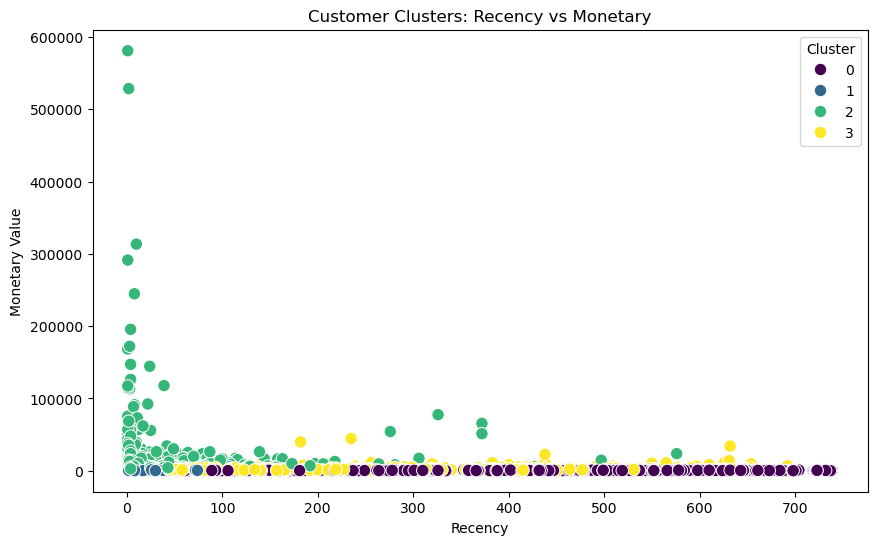

In [63]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=80
)

plt.title("Customer Clusters: Recency vs Monetary")
plt.xlabel("Recency")
plt.ylabel("Monetary Value")

plt.show()

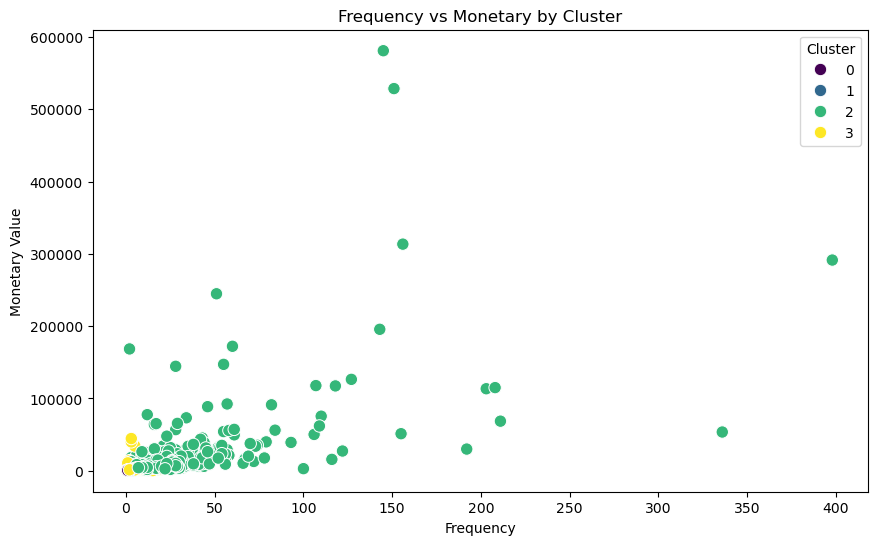

In [64]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=80
)

plt.title("Frequency vs Monetary by Cluster")
plt.xlabel("Frequency")
plt.ylabel("Monetary Value")

plt.show()

In [65]:
cluster_summary = rfm.groupby('Cluster').agg(
    Customers=('Cluster', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Avg_RFM_Score=('RFM_Score', 'mean')
).round(2)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_RFM_Score
Cluster,,,,,
0,1973,394.95,1.38,317.08,4.94
1,1250,28.30,3.05,857.49,9.75
2,1196,27.71,19.28,10731.16,14.06
3,1459,230.07,5.06,1948.50,9.73


In [66]:
cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_RFM_Score
Cluster,,,,,
0,1973,394.95,1.38,317.08,4.94
1,1250,28.30,3.05,857.49,9.75
2,1196,27.71,19.28,10731.16,14.06
3,1459,230.07,5.06,1948.50,9.73


In [67]:
cluster_labels = {
    0: 'Champions',
    1: 'At Risk',
    2: 'Loyal Customers',
    3: 'Lost Customers'
}

In [68]:
rfm['Cluster_Label'] = rfm['Cluster'].map(cluster_labels)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster,Cluster_Label
Customer ID,,,,,,,,,,
12346,326,12,77556.46,2,5,5,12,Loyal Customers,2,Loyal Customers
12347,2,8,4921.53,5,4,5,14,Champions,2,Loyal Customers
12348,75,5,2019.40,3,4,4,11,Loyal Customers,3,Lost Customers
12349,19,4,4428.69,5,3,5,13,Champions,1,At Risk
12350,310,1,334.40,2,1,2,5,At Risk,0,Champions


In [72]:
final_summary = rfm.groupby('Cluster_Label').agg(
    Customers=('Cluster_Label', 'count'),
    Total_Revenue=('Monetary', 'sum'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

final_summary

,Customers,Total_Revenue,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster_Label,,,,,
At Risk,1250,1071864.29,28.30,3.05,857.49
Champions,1973,625601.80,394.95,1.38,317.08
Lost Customers,1459,2842867.24,230.07,5.06,1948.50
Loyal Customers,1196,12834470.94,27.71,19.28,10731.16


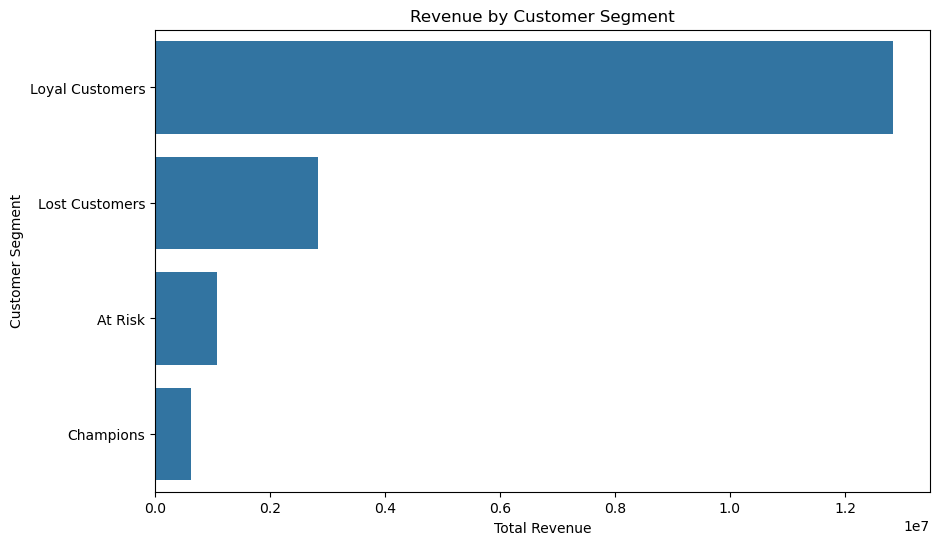

In [73]:
plt.figure(figsize=(10, 6))

segment_order = (
    final_summary
    .sort_values('Total_Revenue', ascending=False)
    .index
)

sns.barplot(
    data=final_summary.loc[segment_order].reset_index(),
    x='Total_Revenue',
    y='Cluster_Label'
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")

plt.show()

In [75]:
rfm_export = rfm.reset_index()

rfm_export.to_csv(
    r"C:\Users\satwika\Desktop\Customer_Segmentation.csv",
    index=False
)

print("Customer segmentation dataset exported successfully!")

Customer segmentation dataset exported successfully!


In [76]:
final_data = pd.read_csv(
    r"C:\Users\satwika\Desktop\Customer_Segmentation.csv"
)

print("Rows:", final_data.shape[0])
print("Columns:", final_data.shape[1])

final_data.head()

Rows: 5878
Columns: 11


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster,Cluster_Label
0,12346,326,12,77556.46,2,5,5,12,Loyal Customers,2,Loyal Customers
1,12347,2,8,4921.53,5,4,5,14,Champions,2,Loyal Customers
2,12348,75,5,2019.40,3,4,4,11,Loyal Customers,3,Lost Customers
3,12349,19,4,4428.69,5,3,5,13,Champions,1,At Risk
4,12350,310,1,334.40,2,1,2,5,At Risk,0,Champions


In [77]:
print("=" * 50)
print("CUSTOMER SEGMENTATION ANALYSIS")
print("=" * 50)

print(f"Total Customers : {rfm.index.nunique():,}")
print(f"Total Revenue   : {df['Revenue'].sum():,.2f}")
print(f"Total Orders    : {df['Invoice'].nunique():,}")
print(f"Total Products  : {df['StockCode'].nunique():,}")
print(f"Total Countries : {df['Country'].nunique():,}")

print("=" * 50)

CUSTOMER SEGMENTATION ANALYSIS
Total Customers : 5,878
Total Revenue   : 17,374,804.27
Total Orders    : 36,969
Total Products  : 4,631
Total Countries : 41


In [78]:
import os
print(os.getcwd())

C:\Users\satwika
